In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import scipy as sp
from scipy.signal import find_peaks, butter, filtfilt

In [5]:
# Importar e visualizar os dados do acelerômetro
data = pd.read_csv('leituras_arduino___.txt',sep = ',')
new_columns = ['x', 'y', 'z','t']
data.columns = new_columns
data.head()

,x,y,z,t
0,-0.20,-0.38,0.91,0.10
1,-0.40,-0.38,0.88,0.14
2,-0.21,-0.38,0.87,0.14
3,-0.19,-0.38,0.87,0.19
4,-0.20,-0.41,0.88,0.25


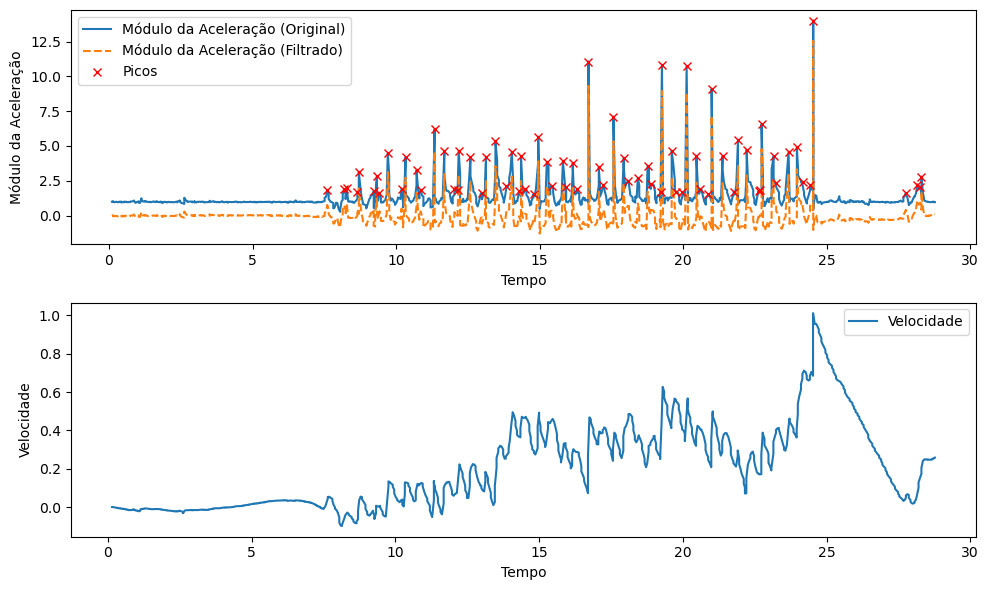

Índices dos picos: [229 247 250 261 263 277 281 284 293 307 311 323 327 339 351 363 365 367
 379 391 395 406 418 423 431 433 437 447 451 460 465 477 480 488 492 505
 516 521 532 541 546 557 567 571 581 583 594 599 606 610 621 625 634 637
 648 661 664 675 687 689 691 703 706 719 728 734 743 746 845 857 860 862]
Valores dos picos: [ 1.83872238  1.89678676  2.01893536  1.66679333  3.15607351  1.73971262
  2.83697021  1.63740649  4.48572179  1.94681792  4.18364673  3.24655202
  1.8403804   6.20749547  4.62058438  1.9271741   1.8640279   4.6393534
  4.21422591  1.62434602  4.23785323  5.32554223  2.12577045  4.59088227
  1.73427218  4.26133782  1.9104188   1.52170956  5.67253911  3.86777714
  2.11664829  3.89495828  2.03091113  3.7473991   1.8870877  11.06732578
  3.4774991   2.17882996  7.11362777  4.13396904  2.49481462  2.69736909
  3.55416657  2.26523729  1.66544288 10.82097038  4.64656863  1.67633529
  1.67555961 10.74229026  4.29922086  1.88345427  1.55322246  9.09469076
  4.26076284 

In [6]:
# Supondo que os dados já estejam carregados
x = np.array(data['x'])
y = np.array(data['y'])
z = np.array(data['z'])
t = np.array(data['t'])

# Calculando o módulo do vetor aceleração
mod = np.sqrt(x**2 + y**2 + z**2)

# Definindo o threshold (limite) para os picos
threshold = 1.5  # Ajuste esse valor conforme necessário

# Encontrando os picos locais no módulo com o threshold
picos, _ = find_peaks(mod, height=threshold)

# Filtro passa-alto Butterworth
# Definindo a frequência de corte (em Hz), e a ordem do filtro
frequencia_corte = 0.1  # Em Hz (ajuste conforme necessário)
ordem_filtro = 4  # Ordem do filtro

# Normalizando a frequência de corte
fs = 1 / (t[1] - t[0])  # Frequência de amostragem (assumindo que t é em segundos)
wn = frequencia_corte / (0.5 * fs)  # Frequência normalizada

# Criando o filtro Butterworth passa-alto
b, a = butter(ordem_filtro, wn, btype='high', analog=False)

# Aplicando o filtro Butterworth no sinal
mod_filtrado = filtfilt(b, a, mod)

# Cálculo da velocidade (integração numérica do módulo da aceleração filtrado)
velocidade = sp.integrate.cumulative_simpson(mod_filtrado, dx=np.mean(np.diff(t)))

# Opcional: visualização
plt.figure(figsize=(10, 6))

# Gráfico do módulo da aceleração original e filtrado
plt.subplot(2, 1, 1)
plt.plot(t, mod, label='Módulo da Aceleração (Original)')
plt.plot(t, mod_filtrado, label='Módulo da Aceleração (Filtrado)', linestyle='--')
plt.plot(t[picos], mod[picos], 'rx', label='Picos')
plt.xlabel('Tempo')
plt.ylabel('Módulo da Aceleração')
plt.legend()

# Gráfico da velocidade
plt.subplot(2, 1, 2)
plt.plot(t[1:], velocidade, label='Velocidade')
plt.xlabel('Tempo')
plt.ylabel('Velocidade')
plt.legend()

plt.tight_layout()
plt.show()

# Picos encontrados
print("Índices dos picos:", picos)
print("Valores dos picos:", mod[picos])
print("Velocidade calculada:", velocidade)
